## 1 data

In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from arch import arch_model
from IPython.display import HTML, display
from statsmodels.tsa.api import VAR

In [3]:
tickers = {
    "US_SP500": "^GSPC",
    "EUROSTOXX50": "^STOXX50E",
    "JAPAN_NIKKEI": "^N225",
    "CHINA_HSI": "^HSI",
    "INDIA_NIFTY": "^NSEI"
}
tickers_list = list(tickers.values())

In [4]:
data = yf.download(tickers = tickers_list, start="2000-01-01")['Close'].dropna()

data = data.resample("W-FRI").last().dropna()

returns = np.log(data/data.shift(1)).dropna()
returns = 100*returns

C:\Users\matti\AppData\Local\Temp\ipykernel_25344\194985887.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers = tickers_list, start="2000-01-01")['Close'].dropna()
[*********************100%***********************]  5 of 5 completed


In [5]:
returns

Ticker,^GSPC,^HSI,^N225,^NSEI,^STOXX50E
Date,,,,,
2007-09-28,0.065520,4.902976,2.858826,3.729049,0.259593
2007-10-05,1.999844,2.506949,1.650517,3.223494,1.665761
2007-10-12,0.269930,3.553759,1.547474,4.568302,0.463761
2007-10-19,-1.400470,2.149808,-1.307208,-1.433334,-1.250862
2007-10-26,-0.312154,3.140949,-3.573294,6.358611,0.448053
...,...,...,...,...,...
2025-12-19,0.103790,-1.108100,-2.649726,-0.309724,0.690534
2025-12-26,1.095594,0.324927,1.812819,0.808350,-0.192366
2026-01-02,-0.196288,0.311683,-0.145685,-0.914508,0.813143


In [6]:
rows = []
for i in returns.columns:
    x = returns[i]
    rows.append({
        "Mean": np.mean(x),
        "Median": np.median(x),
        "Max": np.max(x),
        "Min": np.min(x),
        "Std": np.std(x, ddof=1),
        "Skewness": x.skew(),
        # pandas comupute the excess Kurtosis = Kurtosi - 3 (VERIFICARE)
        "Kurtosis": x.kurtosis() + 3,          
        "Obs": len(x),
    })

table = pd.DataFrame(rows, index=returns.columns)
print(table)

               Mean    Median        Max        Min       Std  Skewness  \
Ticker                                                                    
^GSPC      0.158620  0.314078  11.423675 -20.083751  2.501538 -0.921568   
^HSI       0.003980  0.198651  17.794564 -17.815414  3.113591 -0.120713   
^N225      0.125221  0.236520  15.817097 -27.884405  3.069613 -1.049545   
^NSEI      0.174855  0.366056  14.356831 -18.625285  2.713985 -0.656542   
^STOXX50E  0.033698  0.322758  11.517829 -25.131027  3.041254 -1.318951   

            Kurtosis  Obs  
Ticker                     
^GSPC      10.456110  955  
^HSI        5.929644  955  
^N225      12.477217  955  
^NSEI       9.657975  955  
^STOXX50E  12.319998  955  


Daily returns exhibit negative skewness and substantial excess kurtosis, indicating heavy tails and deviations from normality. 
We therefore consider GARCH-type models with Student-t distributions and compare them to Gaussian.

La kurtosis “unconditional” è coerente con fat tails, ma è anche influenzata dalla volatilità time-varying; 
per questo la scelta tra Normal e t la confermi con AIC/BIC e residui standardizzati.

## 2 choose of the model

In [7]:
y = returns["^GSPC"]
model = arch_model(
    y,
    mean="Constant",     
    vol="GARCH",       
    p=1,
    q=1,
    dist="normal"     
)

res = model.fit(disp="off")
print(res.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                  ^GSPC   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2074.38
Distribution:                  Normal   AIC:                           4156.76
Method:            Maximum Likelihood   BIC:                           4176.21
                                        No. Observations:                  955
Date:                Sat, Jan 17 2026   Df Residuals:                      954
Time:                        23:00:00   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.2987  6.035e-02      4.950  7.407e-07 [  0.180,  0.41

In [8]:
models = [
    ("GARCH(1,1)",  "GARCH",  1, 0, 1, "normal"),
    ("EGARCH(1,1)", "EGARCH", 1, 0, 1, "normal"),
    ("GJR(1,1)",    "GARCH",  1, 1, 1, "normal"),
    ("GARCH(1,1)-t",  "GARCH",  1, 0, 1, "t"),
    ("EGARCH(1,1)-t", "EGARCH", 1, 0, 1, "t"),
     ("GJR(1,1)-t",    "GARCH",  1, 1, 1, "t"),
]

In [9]:
results = {}

for name, vol, p, o, q, dist in models:
    model = arch_model(
        y,
        mean="Constant",
        vol=vol,
        p=p,
        o=o,
        q=q,
        dist=dist
    )
    
    res = model.fit(disp="off") # maximize the log-likelihood, we estimate the parameters, compute the std errors, AIC, BIC
    results[name] = res

In [10]:
summary = pd.DataFrame(
    {
        name: {
            "LogLik": res.loglikelihood,
            "k": res.num_params,
            "AIC": res.aic,
            "BIC": res.bic
        }
        for name, res in results.items()
    }
).T

print(summary.sort_values("AIC"))

                    LogLik    k          AIC          BIC
GJR(1,1)-t    -2023.682465  6.0  4059.364931  4088.535199
GARCH(1,1)-t  -2045.840816  5.0  4101.681632  4125.990189
EGARCH(1,1)-t -2046.595732  5.0  4103.191464  4127.500021
GJR(1,1)      -2052.317825  5.0  4114.635649  4138.944206
EGARCH(1,1)   -2072.456807  4.0  4152.913614  4172.360460
GARCH(1,1)    -2074.381210  4.0  4156.762420  4176.209265


In [11]:
def fit_models(y):
    models = [
        ("GARCH(1,1)",   "GARCH",  1, 0, 1, "normal"),
        ("EGARCH(1,1)",  "EGARCH", 1, 0, 1, "normal"),
        ("GJR(1,1)",     "GARCH",  1, 1, 1, "normal"),
        ("GARCH(1,1)-t", "GARCH",  1, 0, 1, "t"),
        ("EGARCH(1,1)-t","EGARCH", 1, 0, 1, "t"),
        ("GJR(1,1)-t",   "GARCH",  1, 1, 1, "t"),
    ]
    
    rows=[]
    
    for name, vol, p, o, q, dist in models:
        model = arch_model(
            y,
            mean="Constant",
            vol=vol,
            p=p,
            o=o,
            q=q,
            dist=dist
    )
        res = model.fit(disp="off")
        rows.append({
            "Model": name,
            "LogLik": res.loglikelihood,
            "k": res.num_params,
            "AIC": res.aic,
            "BIC": res.bic })
    
    summary = (pd.DataFrame(rows)
               .sort_values(["BIC","AIC"])
               .reset_index(drop=True))
    return summary 

In [12]:
summary_sp = fit_models(returns["^GSPC"])
summary_sp

,Model,LogLik,k,AIC,BIC
0,"GJR(1,1)-t",-2023.682465,6,4059.364931,4088.535199
1,"GARCH(1,1)-t",-2045.840816,5,4101.681632,4125.990189
2,"EGARCH(1,1)-t",-2046.595732,5,4103.191464,4127.500021
3,"GJR(1,1)",-2052.317825,5,4114.635649,4138.944206
4,"EGARCH(1,1)",-2072.456807,4,4152.913614,4172.360460
5,"GARCH(1,1)",-2074.381210,4,4156.762420,4176.209265


In [13]:
summary_dx = fit_models(returns["^STOXX50E"])
summary_dx

,Model,LogLik,k,AIC,BIC
0,"GJR(1,1)-t",-2248.560733,6,4509.121466,4538.291734
1,"EGARCH(1,1)-t",-2260.339167,5,4530.678334,4554.986891
2,"GARCH(1,1)-t",-2261.065331,5,4532.130663,4556.439220
3,"GJR(1,1)",-2291.228379,5,4592.456759,4616.765315
4,"EGARCH(1,1)",-2309.965890,4,4627.931779,4647.378625
5,"GARCH(1,1)",-2314.864042,4,4637.728084,4657.174929


In [14]:
summary_ft = fit_models(returns["^N225"])
summary_ft

,Model,LogLik,k,AIC,BIC
0,"GJR(1,1)-t",-2312.786856,6,4637.573712,4666.743980
1,"GARCH(1,1)-t",-2322.877097,5,4655.754193,4680.062750
2,"EGARCH(1,1)-t",-2324.524514,5,4659.049029,4683.357586
3,"GJR(1,1)",-2327.030461,5,4664.060921,4688.369478
4,"GARCH(1,1)",-2350.199585,4,4708.399170,4727.846015
5,"EGARCH(1,1)",-2352.533167,4,4713.066333,4732.513179


In [15]:
summary_ft = fit_models(returns["^HSI"])
summary_ft

,Model,LogLik,k,AIC,BIC
0,"GJR(1,1)-t",-2361.630262,6,4735.260524,4764.430792
1,"GARCH(1,1)-t",-2369.167154,5,4748.334307,4772.642864
2,"EGARCH(1,1)-t",-2369.775860,5,4749.551719,4773.860276
3,"GJR(1,1)",-2374.098972,5,4758.197945,4782.506502
4,"EGARCH(1,1)",-2381.667419,4,4771.334838,4790.781683
5,"GARCH(1,1)",-2382.008104,4,4772.016208,4791.463053


In [16]:
summary_ft = fit_models(returns["^NSEI"])
summary_ft

,Model,LogLik,k,AIC,BIC
0,"GJR(1,1)-t",-2131.682031,6,4275.364062,4304.534330
1,"GARCH(1,1)-t",-2141.739000,5,4293.478001,4317.786557
2,"GJR(1,1)",-2141.949165,5,4293.898329,4318.206886
3,"EGARCH(1,1)-t",-2144.230101,5,4298.460202,4322.768758
4,"GARCH(1,1)",-2156.059668,4,4320.119336,4339.566182
5,"EGARCH(1,1)",-2162.105146,4,4332.210292,4351.657137


## estimate volatility with GJR-t 

In [17]:
def gjrt_estimate(y):
    model = arch_model(
        y,
        mean ="Constant",
        vol = "GARCH",
        p = 1,
        o = 1,
        q = 1,
        dist = "t")
    res = model.fit(disp="off")
    sigma = res.conditional_volatility
    return sigma, res

In [18]:
vol_data = pd.DataFrame()

vol_data["SP500"], res_sp = gjrt_estimate(returns["^GSPC"].squeeze())
vol_data["EUROSTOXX50"],   res_eu = gjrt_estimate(returns["^STOXX50E"].squeeze())
vol_data["JAPAN_NIKKEI"],  res_jp = gjrt_estimate(returns["^N225"].squeeze())
vol_data["CHINA_HSI"],   res_ch = gjrt_estimate(returns["^HSI"].squeeze())
vol_data["INDIA_NIFTY"],  res_em = gjrt_estimate(returns["^NSEI"].squeeze())


vol_data = vol_data.dropna()

In [19]:
vol_data

,SP500,EUROSTOXX50,JAPAN_NIKKEI,CHINA_HSI,INDIA_NIFTY
Date,,,,,
2007-09-28,2.705955,2.752053,3.271367,3.940091,4.249142
2007-10-05,2.387939,2.601660,2.937707,3.841930,3.995028
2007-10-12,2.123024,2.468287,2.702211,3.731204,3.752865
2007-10-19,1.906990,2.350438,2.539775,3.631900,3.567799
2007-10-26,2.034416,2.330172,2.557269,3.529049,3.405618
...,...,...,...,...,...
2025-12-19,1.705222,2.121364,2.557748,2.728845,1.464080
2025-12-26,1.575052,2.046299,2.868658,2.685865,1.443145
2026-01-02,1.469786,1.987119,2.654226,2.622913,1.409993


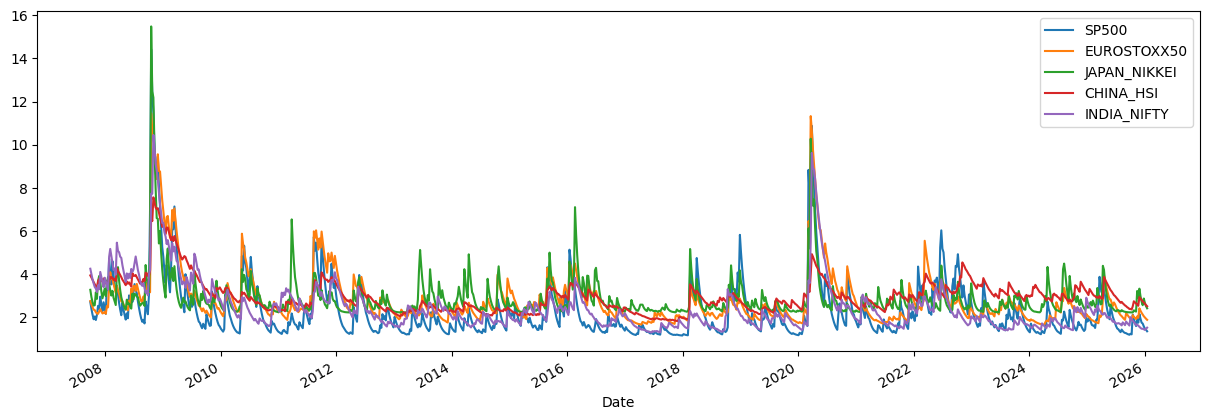

In [20]:
vol_data.plot(figsize=(15,5))
plt.show()

## VAR and optimal lag

In [21]:
model_var = VAR(vol_data)

#optimal p lags
results=[]
max_p = 12
for p in range(1, max_p+1):
    res = model_var.fit(p)
    results.append({ "p" : p, 
                    "AIC" : res.aic, 
                    "BIC": res.bic})


C:\Users\matti\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


In [22]:
ic_table = pd.DataFrame(results).set_index("p")
print(ic_table)

          AIC        BIC
p                       
1  -12.345515 -12.192664
2  -12.388601 -12.108140
3  -12.451243 -12.042961
4  -12.458944 -11.922626
5  -12.431146 -11.766577
6  -12.411389 -11.618356
7  -12.422862 -11.501149
8  -12.398550 -11.347942
9  -12.379334 -11.199613
10 -12.351143 -11.042093
11 -12.319835 -10.881238
12 -12.289818 -10.721456


In [23]:
p_aic = ic_table["AIC"].idxmin()
p_bic = ic_table["BIC"].idxmin()
p_aic, p_bic

(4, 1)

In [24]:
p_opt = p_bic
var_res = model_var.fit(p_opt)

print(var_res.summary())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sat, 17, Jan, 2026
Time:                     23:00:15
--------------------------------------------------------------------
No. of Equations:         5.00000    BIC:                   -12.1927
Nobs:                     954.000    HQIC:                  -12.2873
Log likelihood:          -849.526    FPE:                4.34922e-06
AIC:                     -12.3455    Det(Omega_mle):     4.21500e-06
--------------------------------------------------------------------
Results for equation SP500
                     coefficient       std. error           t-stat            prob
----------------------------------------------------------------------------------
const                   0.210888         0.094106            2.241           0.025
L1.SP500                0.929977         0.031261           29.748           0.000
L1.EUROSTOXX50         -0.037434         0.034471   

In [25]:
var_res.is_stable(True)

Eigenvalues of VAR(1) rep
0.7359118640458748
0.9618281733272972
0.8676095739716534
0.8676095739716534
0.8846338216380799


True

## MA representation

In [26]:
H = 8 #horizons
A = var_res.ma_rep(H) # array (H+1, N, N)

## GFEVD

In [36]:
def gfevd_theta(A, cov, H):
    n = cov.shape[0]
    diag = np.diag(cov)
    theta = np.zeros((n, n))

    for i in range(n):
        num = np.zeros(n)
        denom = 0.0
        for h in range(H):
            row_cov = A[h][i, :] @ cov
            num += (row_cov**2) / diag
            denom += row_cov @ A[h][i, :]
        theta[i, :] = num / denom

    return theta / theta.sum(axis=1, keepdims=True)

In [39]:
n = cov.shape[0]
A = var_res.ma_rep(H)          # shape (H, n, n)

cov = var_res.sigma_u.values   # (n, n)
theta = gfevd_theta(A, cov, H)
theta

array([[0.40103876, 0.19792803, 0.15395355, 0.12326124, 0.12381842],
       [0.26516605, 0.31400917, 0.17630757, 0.12536438, 0.11915283],
       [0.22772004, 0.18505134, 0.32758839, 0.14019755, 0.11944268],
       [0.20426843, 0.14713396, 0.17304606, 0.34236313, 0.13318843],
       [0.21253085, 0.16357618, 0.17736496, 0.13937647, 0.30715153]])

In [40]:
TSI = 100 * (theta.sum() - np.trace(theta)) / n
TSI

66.15698051345039

In [41]:
spill_from = 100 * (theta.sum(axis=1) - np.diag(theta))
spill_from

array([59.89612387, 68.59908318, 67.24116107, 65.76368726, 69.28484719])

In [42]:
spill_to = 100 * (theta.sum(axis=0) - np.diag(theta))
spill_to


array([90.96853632, 69.36895169, 68.06721375, 52.81996518, 49.56023564])

In [43]:
spill_net = spill_to - spill_from
spill_net


array([ 31.07241245,   0.76986851,   0.82605268, -12.94372208,
       -19.72461156])

In [44]:
assets = vol_data.columns

spillover_table = pd.DataFrame({
    "FROM": spill_from,
    "TO": spill_to,
    "NET": spill_net
}, index=assets)

spillover_table


,FROM,TO,NET
SP500,59.896124,90.968536,31.072412
EUROSTOXX50,68.599083,69.368952,0.769869
JAPAN_NIKKEI,67.241161,68.067214,0.826053
CHINA_HSI,65.763687,52.819965,-12.943722
INDIA_NIFTY,69.284847,49.560236,-19.724612


## ROLLING WINDOW PLOT

C:\Users\matti\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\matti\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\matti\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\matti\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\matti\AppData\Local\Programs\Python

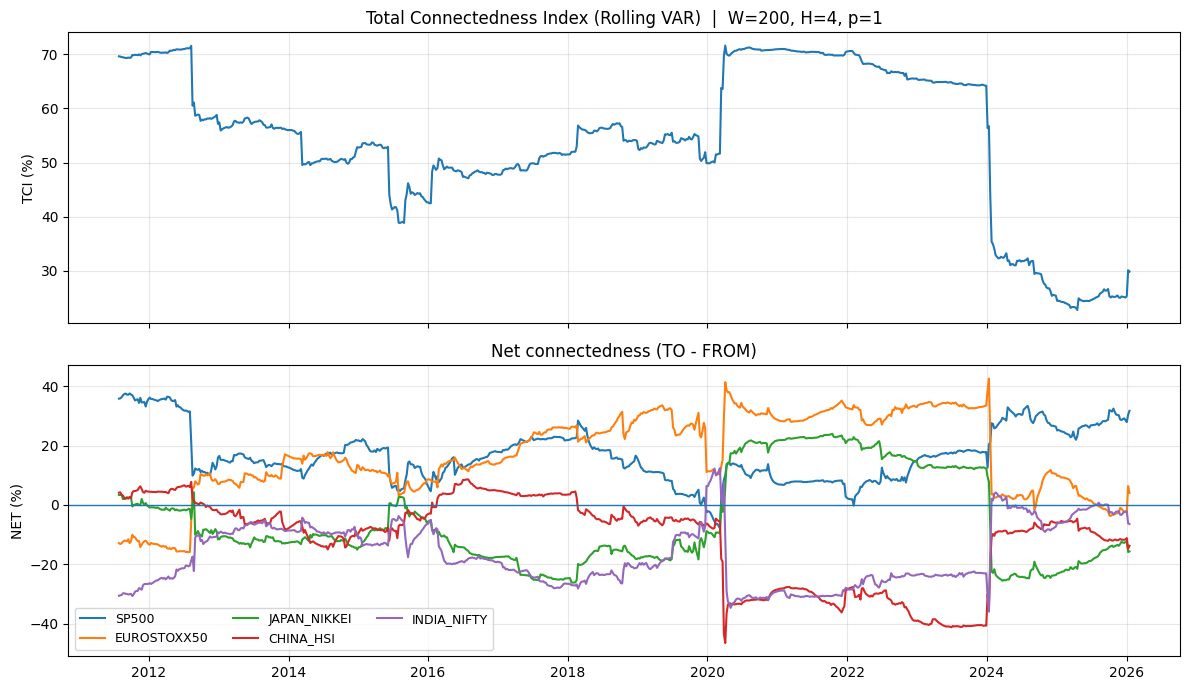

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR

# -----------------------------
# Settings (weekly)
# -----------------------------
W = 200          # rolling window (weeks)  -> try also 150 or 250 for robustness
H = 4            # forecast horizon (weeks) -> baseline 4; robustness 12
# p_opt must be defined (e.g., p_opt = 1)
# vol_data must be a DataFrame with 5 columns and weekly index

# -----------------------------
# GFEVD (generalized FEVD) - cleaner implementation
# -----------------------------
def gfevd_theta(A, cov, H):
    """
    A: array shape (H, n, n) with MA coefficients A[h]
    cov: (n, n) Sigma_u
    returns: theta (n, n), row-normalized
    """
    n = cov.shape[0]
    diag = np.diag(cov)
    theta = np.zeros((n, n))

    for i in range(n):
        num = np.zeros(n)
        denom = 0.0

        for h in range(H):
            row = A[h][i, :]            # (n,)
            row_cov = row @ cov         # (n,), element j = e_i' A[h] cov e_j

            num += (row_cov**2) / diag  # vectorized over j
            denom += row_cov @ row      # scalar = e_i' A[h] cov A[h]' e_i

        theta[i, :] = num / denom

    theta = theta / theta.sum(axis=1, keepdims=True)
    return theta

def dy_measures(theta):
    """
    theta is row-normalized (rows sum to 1)
    returns: TCI, FROM, TO, NET all in percent
    """
    n = theta.shape[0]
    off_diag_sum = theta.sum() - np.trace(theta)
    TCI = 100 * off_diag_sum / n

    FROM = 100 * (theta.sum(axis=1) - np.diag(theta))  # row off-diagonal
    TO   = 100 * (theta.sum(axis=0) - np.diag(theta))  # col off-diagonal
    NET  = TO - FROM

    return TCI, FROM, TO, NET

# -----------------------------
# Rolling DY
# -----------------------------
dates = vol_data.index
assets = vol_data.columns

TCI_series = []
out_dates = []

FROM_list = []
TO_list = []
NET_list = []

for t in range(W, len(vol_data)):
    window_data = vol_data.iloc[t-W:t]

    try:
        var_res = VAR(window_data).fit(p_opt)
        A = var_res.ma_rep(H)
        cov = var_res.sigma_u.values

        theta = gfevd_theta(A, cov, H)
        TCI, FROM, TO, NET = dy_measures(theta)

    except Exception:
        # if VAR fails in a window, store NaNs (keeps alignment)
        TCI = np.nan
        FROM = np.full(len(assets), np.nan)
        TO   = np.full(len(assets), np.nan)
        NET  = np.full(len(assets), np.nan)

    TCI_series.append(TCI)
    FROM_list.append(FROM)
    TO_list.append(TO)
    NET_list.append(NET)
    out_dates.append(dates[t])

# Wrap results into pandas objects
TCI_roll = pd.Series(TCI_series, index=out_dates, name="TCI")
FROM_roll = pd.DataFrame(FROM_list, index=out_dates, columns=assets)
TO_roll   = pd.DataFrame(TO_list,   index=out_dates, columns=assets)
NET_roll  = pd.DataFrame(NET_list,  index=out_dates, columns=assets)

# -----------------------------
# Single figure (two panels)
# -----------------------------
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Top: TCI
ax[0].plot(TCI_roll.index, TCI_roll.values)
ax[0].set_title(f"Total Connectedness Index (Rolling VAR)  |  W={W}, H={H}, p={p_opt}")
ax[0].set_ylabel("TCI (%)")
ax[0].grid(True, alpha=0.3)

# Bottom: NET for all assets
for c in NET_roll.columns:
    ax[1].plot(NET_roll.index, NET_roll[c].values, label=c)
ax[1].axhline(0, linewidth=1)
ax[1].set_title("Net connectedness (TO - FROM)")
ax[1].set_ylabel("NET (%)")
ax[1].grid(True, alpha=0.3)
ax[1].legend(ncol=3, fontsize=9)

plt.tight_layout()
plt.show()


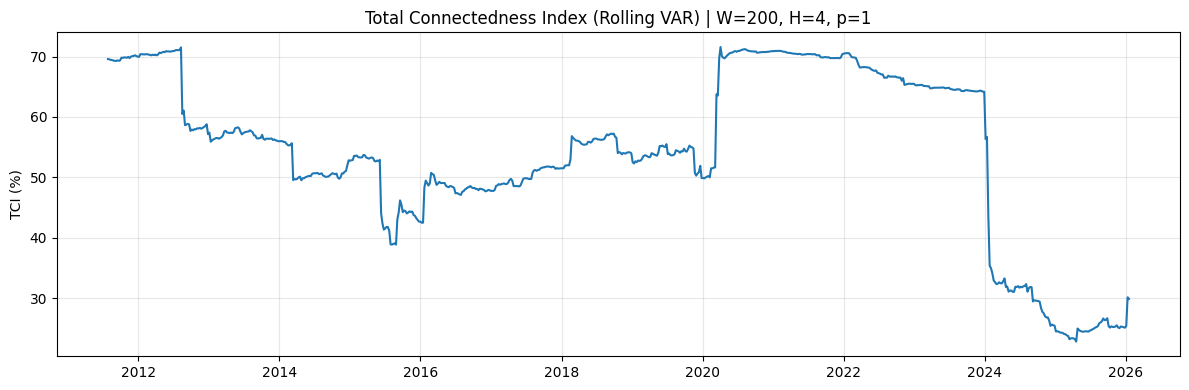

In [46]:


plt.figure(figsize=(12,4))
plt.plot(TCI_roll.index, TCI_roll.values)
plt.title(f"Total Connectedness Index (Rolling VAR) | W={W}, H={4}, p={p_opt}")
plt.ylabel("TCI (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


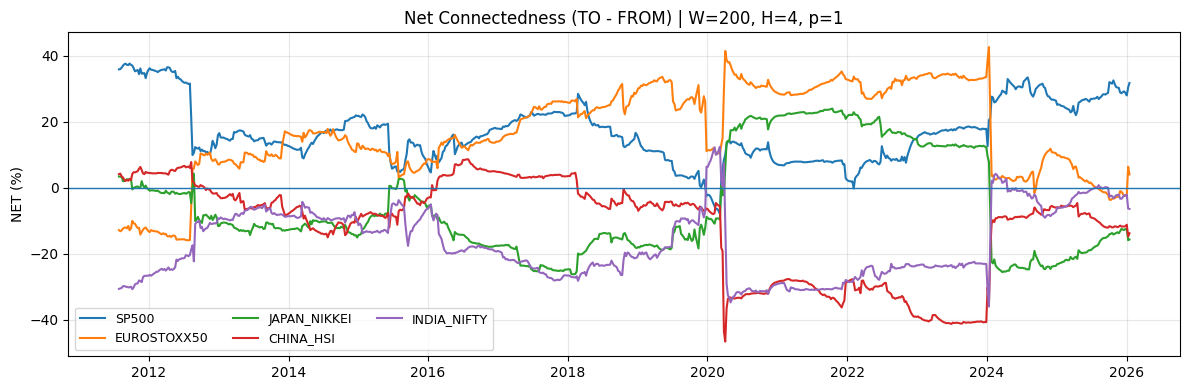

In [47]:

plt.figure(figsize=(12,4))
for c in NET_roll.columns:
    plt.plot(NET_roll.index, NET_roll[c].values, label=c)

plt.axhline(0, linewidth=1)
plt.title(f"Net Connectedness (TO - FROM) | W={W}, H={4}, p={p_opt}")
plt.ylabel("NET (%)")
plt.grid(True, alpha=0.3)
plt.legend(ncol=3, fontsize=9)
plt.tight_layout()
plt.show()
